# NHSN Dialysis Events: Rate Estimation, GLMs, and a Bayesian Hierarchical Model

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/nhsn-dialysis-analytics/blob/main/notebooks/02_rates_bayesian_glm.ipynb)

**Portfolio project 2 of 5** | Role focus: Data Analyst I, NHSN Dialysis Event prevention and surveillance support

---
## How this notebook relates to notebook 01
**Notebook 01 produced and cleaned the data; this notebook analyzes it.** Specifically:

| Link | What happens here |
|---|---|
| Same synthetic world | Section 1 re-runs notebook 01's generator and error injection with the **same seed**, so the facilities, events, and planted errors are identical |
| Same validation rules | Notebook 01's rules (R1-R9) are re-applied, and only **validated** records enter the rate models. This is the realistic order of work: validate first, estimate second |
| Same ground truth | The latent facility risk (`log_effect`) was never shown to any method in notebook 01. Here it is used, **for evaluation only**, to check whether each rate method recovers the truth |
| A leftover problem | Notebook 01 showed that over-reported (but plausible-looking) events cannot be removed by rules. They remain in the data here, a small, realistic contamination the models must tolerate |

If you only open this notebook, it still runs on its own: Section 1 rebuilds everything it needs.
**Runtime:** about 8-12 minutes on a free Colab CPU, almost all of it MCMC sampling (Section 6). Random seeds are fixed.

## Data statement
**No PHI and no real NHSN data.** Everything is simulated, and rates are illustrative. Methods here (rates per 100
patient-months, standardized ratios with exact Poisson intervals, count models with an exposure offset) follow common
surveillance practice, but this is **not** the official NHSN risk-adjustment methodology. Dialysis "events" are
surveillance events, not necessarily infections.

## What this notebook does
| Step | Method | Duty it maps to |
|---|---|---|
| 3 | Rates per 100 patient-months by access type, with exact Poisson intervals | NHSN analyses, user reports |
| 4 | Poisson, negative binomial, and zero-inflated Poisson GLMs with a log(patient-months) offset; overdispersion tests | Quality incentive program analyses |
| 5 | Standardized ratios (SIR) with exact Poisson confidence intervals | Facility reports |
| 6 | **Bayesian hierarchical negative binomial model (PyMC)**: facilities nested in networks, partial pooling | Stable small-facility estimates |
| 7 | Diagnostics: R-hat, ESS, divergences, posterior predictive checks, LOO-CV, calibration | Defensible methods |
| 8 | Shrinkage vs raw SIR, accuracy against the known truth, who gets flagged and why | Avoiding mislabeled facilities |
| 9 | Outputs: facility estimate table, Excel workbook | Reports |

## 0. Setup

In [1]:
import sys, subprocess, importlib, warnings, os, time
warnings.filterwarnings("ignore")

def _ensure(pip_name, import_name=None):
    """Install a package only if it is missing (Colab already has most of these)."""
    try:
        importlib.import_module(import_name or pip_name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

for pip_name in ["numpy", "pandas", "scipy", "matplotlib", "statsmodels", "openpyxl", "pymc", "arviz"]:
    _ensure(pip_name)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import pymc as pm
import arviz as az
from IPython.display import display

SEED = 42
rng = np.random.default_rng(SEED)
np.random.seed(SEED)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 170)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
OUT = "outputs_02"
os.makedirs(OUT, exist_ok=True)
print("pandas", pd.__version__, "| pymc", pm.__version__, "| arviz", az.__version__, "| statsmodels", sm.__version__)

pandas 2.2.3 | pymc 5.28.5 | arviz 0.22.0 | statsmodels 0.15.0


## 1. Rebuild the notebook 01 world and keep only validated records
The next cells are a compact copy of notebook 01 (configuration, generator, error injection, validation rules). They are
collapsed in Colab (`display-mode: form`). **Do not change the seed or the order**, or the data will differ from notebook 01.
In a real repository these functions would live in `src/` and be imported by both notebooks.

In [2]:
#@title Recap from notebook 01: config { display-mode: "form" }
N_FACILITIES = 160
MONTHS = pd.period_range("2023-01", "2024-12", freq="M")      # 24 reporting months
ACCESS = ["AVF", "AVG", "CVC_tunneled", "CVC_nontunneled", "Other"]
EVENT_TYPES = ["positive_blood_culture", "iv_antimicrobial_start", "pus_redness_swelling"]

# Illustrative baseline rates per 100 patient-months, by access type (columns follow EVENT_TYPES order).
BASE_RATE = {
    "AVF":             [0.15, 0.45, 0.10],
    "AVG":             [0.35, 0.90, 0.25],
    "CVC_tunneled":    [1.10, 2.00, 0.40],
    "CVC_nontunneled": [2.50, 3.50, 0.80],
    "Other":           [0.30, 0.80, 0.20],
}

LATE_DAYS = 30           # submission later than this many days after month end counts as late
DUP_WINDOW_DAYS = 21     # same patient + same event type within this window = duplicate (illustrative rule)
MIN_PLAUSIBLE_YEAR = 2015

# Probability each record is hit by an injected error (facility-month level, then event level).
ERR_RATES = dict(
    missing=0.020, patient_typo=0.015, sum_mismatch=0.020, zero_access=0.030, late=0.030, inflation=0.025,
    duplicate=0.020, date_outside=0.015, date_implausible=0.007, access_swapped=0.015,
)
print(f"{N_FACILITIES} facilities x {len(MONTHS)} months = {N_FACILITIES*len(MONTHS):,} facility-months")

160 facilities x 24 months = 3,840 facility-months


In [3]:
#@title Recap from notebook 01: generator { display-mode: "form" }
def make_facilities(n, rng):
    states = ["FL", "GA", "TX", "CA", "NY", "OH", "PA", "IL", "NC", "MI"]
    state_network = {s: f"NW-{(i % 6) + 1:02d}" for i, s in enumerate(states)}   # synthetic network codes
    fac = pd.DataFrame({"facility_id": [f"FAC{i+1:04d}" for i in range(n)]})
    fac["state"] = rng.choice(states, n)
    fac["network"] = fac["state"].map(state_network)
    fac["ownership"] = rng.choice(["Large_chain", "Nonprofit", "Independent"], n, p=[0.60, 0.25, 0.15])
    fac["urban_rural"] = rng.choice(["Urban", "Rural"], n, p=[0.78, 0.22])
    size = rng.lognormal(np.log(65), 0.45, n) * np.where(fac["urban_rural"] == "Rural", 0.7, 1.0)
    fac["mean_census"] = np.clip(size, 15, 250).round().astype(int)
    base_mix = np.array([0.62, 0.13, 0.17, 0.02, 0.06])
    mix = np.vstack([rng.dirichlet(base_mix * 60) for _ in range(n)])
    for j, a in enumerate(ACCESS):
        fac[f"mix_{a}"] = mix[:, j]
    fac["log_effect"] = rng.normal(0, 0.35, n)             # latent facility risk (ground truth, never used as a feature)
    fac["in_collaborative"] = rng.random(n) < 0.40
    return fac


def make_clean_denominator(fac, months, rng):
    rows, mix_cols = [], [f"mix_{a}" for a in ACCESS]
    for f in fac.itertuples(index=False):
        mix = np.array([getattr(f, c) for c in mix_cols]); mix = mix / mix.sum()
        drift = rng.normal(0.002, 0.003)                    # slow census growth/decline
        for t, m in enumerate(months):
            start = m.to_timestamp()
            end = (m + 1).to_timestamp() - pd.Timedelta(days=1)
            total = max(8, int(round(f.mean_census * (1 + drift * t) * (1 + rng.normal(0, 0.025)))))
            counts = rng.multinomial(total, mix)
            delay = int(np.clip(rng.gamma(2.0, 5.0), 3, 28))   # typical on-time submission
            rows.append({"facility_id": f.facility_id, "month": start,
                         "report_date": end + pd.Timedelta(days=delay), "patients_total": total,
                         **{f"n_{a}": int(c) for a, c in zip(ACCESS, counts)}})
    return pd.DataFrame(rows)


def make_clean_events(fac, den, rng):
    info = fac.set_index("facility_id")[["log_effect", "in_collaborative", "mean_census"]].to_dict("index")
    collab_start, rows = pd.Timestamp("2024-01-01"), []
    for r in den.itertuples(index=False):
        f = info[r.facility_id]
        ndays = r.month.days_in_month
        post = bool(f["in_collaborative"]) and r.month >= collab_start
        shock = rng.gamma(20, 1 / 20)                         # monthly extra-Poisson variation
        pool = int(f["mean_census"] * 1.6)
        for a in ACCESS:
            n_a = getattr(r, f"n_{a}")
            if n_a == 0:
                continue
            mult = 0.7 if (post and a.startswith("CVC")) else 1.0
            for k, et in enumerate(EVENT_TYPES):
                lam = n_a * BASE_RATE[a][k] / 100 * np.exp(f["log_effect"]) * shock * mult
                for _ in range(rng.poisson(lam)):
                    rows.append({"facility_id": r.facility_id, "month": r.month,
                                 "patient_id": f"{r.facility_id}-P{rng.integers(1, pool + 1):04d}",
                                 "event_type": et, "access_type": a,
                                 "event_date": r.month + pd.Timedelta(days=int(rng.integers(0, ndays)))})
    return pd.DataFrame(rows)


def enforce_dup_window(ev, window=DUP_WINDOW_DAYS):
    """Clean data should already obey the duplicate-event rule: drop a repeat for the same patient/type inside the window."""
    ev = ev.sort_values(["facility_id", "patient_id", "event_type", "event_date"]).reset_index(drop=True)
    keep, last_key, last_date = np.ones(len(ev), bool), None, None
    for i, (fid, pid, et, d) in enumerate(zip(ev.facility_id, ev.patient_id, ev.event_type, ev.event_date)):
        key = (fid, pid, et)
        if key == last_key and (d - last_date).days <= window:
            keep[i] = False
            continue
        last_key, last_date = key, d
    return ev[keep].reset_index(drop=True)


fac = make_facilities(N_FACILITIES, rng)
den_clean = make_clean_denominator(fac, MONTHS, rng)
ev_clean = enforce_dup_window(make_clean_events(fac, den_clean, rng))
ev_clean = ev_clean.sort_values(["facility_id", "month", "event_date"]).reset_index(drop=True)
ev_clean.insert(0, "event_id", [f"EV{i+1:06d}" for i in range(len(ev_clean))])

In [4]:
#@title Recap from notebook 01: error injection { display-mode: "form" }
def _append_label(ev, mask, label):
    cur = ev.loc[mask, "err_event"]
    ev.loc[mask, "err_event"] = np.where(cur == "", label, cur + "|" + label)


def inject_errors(den_c, ev_c, rng, rates=ERR_RATES):
    den, ev = den_c.copy(), ev_c.copy()
    n = len(den)
    cnt_cols = [f"n_{a}" for a in ACCESS]
    month_end = den["month"] + pd.offsets.MonthEnd(0)

    T = pd.DataFrame({"facility_id": den.facility_id, "month": den.month})
    for k in ["missing", "patient_typo", "sum_mismatch", "zero_access", "late", "inflation"]:
        T[k] = rng.random(n) < rates[k]

    # --- facility-month errors on the denominator ---
    m = T.patient_typo.to_numpy()
    den.loc[m, ["patients_total"] + cnt_cols] = den.loc[m, ["patients_total"] + cnt_cols] * 10

    m = T.sum_mismatch.to_numpy()
    factor = 1 + rng.choice([-1, 1], m.sum()) * rng.uniform(0.08, 0.20, m.sum())
    den.loc[m, "patients_total"] = (den.loc[m, "patients_total"] * factor).round().astype(int)

    ev_by_key = ev_c.groupby(["facility_id", "month"])["access_type"].apply(list).to_dict()
    za_map = {}
    for i in np.flatnonzero(T.zero_access.to_numpy()):
        key = (den.at[i, "facility_id"], den.at[i, "month"])
        cands = [a for a in set(ev_by_key.get(key, [])) if a != "AVF" and den_c.at[i, f"n_{a}"] > 0]
        if not cands:
            T.at[i, "zero_access"] = False
            continue
        a = cands[int(rng.integers(len(cands)))]
        den.at[i, "n_AVF"] += den.at[i, f"n_{a}"]       # patients moved to AVF; total stays consistent
        den.at[i, f"n_{a}"] = 0
        za_map[key] = a

    m = T.late.to_numpy()
    den.loc[m, "report_date"] = month_end[m] + pd.to_timedelta(rng.integers(35, 91, m.sum()), unit="D")

    # --- event-level errors ---
    ev = ev.merge(den[["facility_id", "month", "report_date"]], on=["facility_id", "month"], how="left")
    ev["err_event"] = ""
    N = len(ev)
    k_out, k_imp, k_swap = (int(N * rates[x]) for x in ("date_outside", "date_implausible", "access_swapped"))
    perm = rng.permutation(N)
    i_out, i_imp = perm[:k_out], perm[k_out:k_out + k_imp]
    i_swap = perm[k_out + k_imp:k_out + k_imp + k_swap]
    i_dup = rng.choice(perm[k_out + k_imp + k_swap:], int(N * rates["duplicate"]), replace=False)

    shift = (rng.choice([-1, 1], k_out) * rng.integers(35, 70, k_out))
    ev.loc[i_out, "event_date"] = ev.loc[i_out, "event_date"].to_numpy() + pd.to_timedelta(shift, unit="D").to_numpy()
    half = len(i_imp) // 2
    ev.loc[i_imp[:half], "event_date"] = pd.Timestamp("1900-01-01")
    ev.loc[i_imp[half:], "event_date"] = ev.loc[i_imp[half:], "report_date"] + pd.Timedelta(days=180)
    ev.loc[i_swap, "access_type"] = [rng.choice([x for x in ACCESS if x != a]) for a in ev.loc[i_swap, "access_type"]]
    for idx, lab in [(i_out, "date_outside_month"), (i_imp, "date_implausible"), (i_swap, "access_swapped")]:
        ev.loc[idx, "err_event"] = lab

    dups = ev.loc[i_dup].copy()
    dups["event_id"] = "EVD" + dups["event_id"].str[2:]
    shifted = dups["event_date"] + pd.to_timedelta(rng.integers(1, 15, len(dups)), unit="D")
    dups["event_date"] = pd.concat([shifted, dups["month"] + pd.offsets.MonthEnd(0)], axis=1).min(axis=1)
    dups["err_event"] = "duplicate"

    # over-reporting: valid-looking extra events for new patient IDs, so no event-level rule can catch them
    extra, c = [], 0
    for i in np.flatnonzero(T.inflation.to_numpy()):
        r = den_c.iloc[i]
        w = np.array([r[f"n_{a}"] * sum(BASE_RATE[a]) for a in ACCESS], float)
        for _ in range(int(rng.integers(3, 8))):
            c += 1
            a = ACCESS[int(rng.choice(len(ACCESS), p=w / w.sum()))]
            extra.append({"event_id": f"EVX{c:06d}", "facility_id": r.facility_id, "month": r.month,
                          "patient_id": f"{r.facility_id}-X{c:05d}", "event_type": str(rng.choice(EVENT_TYPES)),
                          "access_type": a,
                          "event_date": r.month + pd.Timedelta(days=int(rng.integers(0, r.month.days_in_month))),
                          "report_date": den.at[i, "report_date"], "err_event": "inflated_valid"})
    ev = pd.concat([ev, dups, pd.DataFrame(extra)], ignore_index=True)

    # label events caused by facility-month problems, then apply missing denominators
    zero_flag = np.array([za_map.get((f, mo)) == a for f, mo, a in zip(ev.facility_id, ev.month, ev.access_type)])
    _append_label(ev, zero_flag, "den_zero_access")
    miss_keys = set(zip(T.loc[T.missing, "facility_id"], T.loc[T.missing, "month"]))
    _append_label(ev, np.array([k in miss_keys for k in zip(ev.facility_id, ev.month)]), "no_denominator")

    den_sub = den.loc[~T.missing.to_numpy()].reset_index(drop=True)
    truth_ev = ev[["event_id", "err_event"]].copy()
    ev_sub = ev.drop(columns="err_event").sort_values(["facility_id", "month", "event_id"]).reset_index(drop=True)
    T["has_fm_error"] = T[["patient_typo", "sum_mismatch", "zero_access", "late", "inflation"]].any(axis=1)
    return den_sub, ev_sub, truth_ev, T


den, ev, truth_ev, truth_fm = inject_errors(den_clean, ev_clean, rng)

In [5]:
#@title Recap from notebook 01: rule registry { display-mode: "form" }
RULES = pd.DataFrame([
    ("R1_date_outside_month", "event", 2, "Event date falls outside the reporting month it was entered under",
     "Hard stop at data entry when event date is outside the selected reporting month",
     "State that the event date, not the entry date, determines the reporting month."),
    ("R2_date_implausible", "event", 3, f"Event date before {MIN_PLAUSIBLE_YEAR} or after the submission date",
     "Block future dates and dates before facility enrollment",
     "Remind users that placeholder dates (for example 01/01/1900) must never be used."),
    ("R3_no_denominator", "event", 3, "Event reported for a facility-month with no submitted denominator",
     "Prevent saving events for a month until its denominator is submitted (or show a blocking alert)",
     "Add a step: complete the monthly denominator before entering events."),
    ("R4_zero_access_denominator", "event", 2, "Event access type has zero patients in that month's denominator",
     "Cross-field warning when event access type has a zero denominator count",
     "Clarify that denominator access-type counts must reflect each patient's access on the first two working days."),
    ("R5_duplicate_21d", "event", 2, f"Same patient and event type repeated within {DUP_WINDOW_DAYS} days",
     "Possible-duplicate alert that shows the earlier event at entry",
     "Add a worked example of the repeat-event window to the form instructions (confirm against current protocol)."),
    ("R6_missing_month", "facility-month", 2, "Enrolled facility has no denominator for a reporting month",
     "Automated missing-data report and reminder to facilities",
     "Add a monthly 'no events to report' attestation pathway."),
    ("R7_events_exceed_patients", "facility-month", 3, "Events for an access type exceed patients in that access category",
     "Numerator/denominator consistency check on submit",
     "Explain how event access type maps to denominator categories."),
    ("R8a_access_sum_mismatch", "facility-month", 2, "Total patients does not equal the sum of access-type counts",
     "Auto-calculate the total from access-type fields (read-only total)",
     "Clarify that the total is the sum of the access-type rows."),
    ("R8b_patient_count_outlier", "facility-month", 2, "Patient count is an outlier vs the facility's own history (robust |z| > 5)",
     "Soft warning when census differs sharply from prior months, with confirm button",
     "Add guidance for confirming unusually large or small census values."),
    ("R9_late_submission", "facility-month", 1, f"Submission more than {LATE_DAYS} days after month end",
     "Timeliness dashboard and automatic reminders at day 20 and day 28",
     "State the submission deadline prominently on the form."),
], columns=["rule_id", "level", "severity", "description", "proposed_modification", "form_instruction_edit"])

In [6]:
#@title Recap from notebook 01: validation functions { display-mode: "form" }
ACC_N = [f"n_{a}" for a in ACCESS]
EVENT_RULES = ["R1_date_outside_month", "R2_date_implausible", "R3_no_denominator", "R4_zero_access_denominator", "R5_duplicate_21d"]


def validate_events(ev, den):
    """Return the event line list with one boolean column per event-level rule."""
    e = ev.merge(den[["facility_id", "month"] + ACC_N], on=["facility_id", "month"], how="left", indicator=True)
    e["R3_no_denominator"] = e["_merge"].eq("left_only")
    a_idx = e["access_type"].map({a: i for i, a in enumerate(ACCESS)}).to_numpy()
    n_for_access = e[ACC_N].to_numpy(float)[np.arange(len(e)), a_idx]
    e["R4_zero_access_denominator"] = (~e["R3_no_denominator"]) & (np.nan_to_num(n_for_access, nan=1) == 0)
    e["R1_date_outside_month"] = e["event_date"].dt.to_period("M") != e["month"].dt.to_period("M")
    e["R2_date_implausible"] = (e["event_date"].dt.year < MIN_PLAUSIBLE_YEAR) | (e["event_date"] > e["report_date"])
    s = e.sort_values(["facility_id", "patient_id", "event_type", "event_date", "event_id"])
    same = (s[["facility_id", "patient_id", "event_type"]].shift().eq(s[["facility_id", "patient_id", "event_type"]]).all(axis=1))
    close = (s["event_date"] - s["event_date"].shift()).dt.days.between(0, DUP_WINDOW_DAYS)
    dup_ids = set(s.loc[same & close, "event_id"])
    e["R5_duplicate_21d"] = e["event_id"].isin(dup_ids)
    e["any_event_rule"] = e[EVENT_RULES].any(axis=1)
    return e.drop(columns=ACC_N + ["_merge"])


def validate_facility_months(den, ev_flags, months, fac_ids):
    grid = pd.MultiIndex.from_product([fac_ids, [m.to_timestamp() for m in months]],
                                      names=["facility_id", "month"]).to_frame(index=False)
    d = grid.merge(den, on=["facility_id", "month"], how="left")
    d["R6_missing_month"] = d["patients_total"].isna()
    present = ~d["R6_missing_month"]

    cnt = ev_flags.pivot_table(index=["facility_id", "month"], columns="access_type", values="event_id",
                               aggfunc="count", fill_value=0).reindex(columns=ACCESS, fill_value=0)
    cnt.columns = [f"ev_{a}" for a in ACCESS]
    d = d.merge(cnt.reset_index(), on=["facility_id", "month"], how="left")
    ev_cols = [f"ev_{a}" for a in ACCESS]
    d[ev_cols] = d[ev_cols].fillna(0).astype(int)
    d["events_total"] = d[ev_cols].sum(axis=1)

    d["R4_any"] = d.merge(ev_flags.groupby(["facility_id", "month"])["R4_zero_access_denominator"].any().rename("x").reset_index(),
                          on=["facility_id", "month"], how="left")["x"].fillna(False).astype(bool).to_numpy()
    d["R7_events_exceed_patients"] = present & (d[ev_cols].to_numpy() > d[ACC_N].fillna(0).to_numpy()).any(axis=1)
    d["R8a_access_sum_mismatch"] = present & (d["patients_total"] != d[ACC_N].sum(axis=1))
    lp = np.log(d["patients_total"].clip(lower=1))
    dev = lp - lp.groupby(d["facility_id"]).transform("median")
    mad = dev.abs().groupby(d["facility_id"]).transform("median")
    d["log_pat_dev"] = dev
    d["robust_z_patients"] = dev / np.maximum(1.4826 * mad, 0.03)       # floor avoids dividing by ~0
    d["R8b_patient_count_outlier"] = present & (d["robust_z_patients"].abs() > 5)
    d["delay_days"] = (d["report_date"] - (d["month"] + pd.offsets.MonthEnd(0))).dt.days
    d["R9_late_submission"] = present & (d["delay_days"] > LATE_DAYS)
    d["rule_fm_count"] = d[["R4_any", "R7_events_exceed_patients", "R8a_access_sum_mismatch",
                            "R8b_patient_count_outlier", "R9_late_submission"]].sum(axis=1)
    d["rule_fm_flag"] = d["rule_fm_count"] > 0
    return d


E = validate_events(ev, den)
D = validate_facility_months(den, E, MONTHS, fac.facility_id.tolist())

In [7]:
print(f"Recap done: {len(fac)} facilities, {len(den):,} denominator rows, {len(ev):,} submitted events; "
      f"{int(E.any_event_rule.sum())} events and {int(D.rule_fm_flag.sum())} facility-months flagged by the rules")

Recap done: 160 facilities, 3,758 denominator rows, 4,365 submitted events; 316 events and 313 facility-months flagged by the rules


In [8]:
# Validated analysis data: drop events failing R1-R5, and facility-months that are missing or fail the facility-month rules.
# (Same filtering as the funnel plot in notebook 01.)
bad_fm = D.R6_missing_month | D.rule_fm_flag
bad_keys = set(zip(D.loc[bad_fm, "facility_id"], D.loc[bad_fm, "month"]))
ev_ok = E[~E.any_event_rule & ~pd.Series(list(zip(E.facility_id, E.month))).isin(bad_keys).to_numpy()].copy()
d_ok = D[~bad_fm].copy()

# Long table: one row per facility-month x access type, with patient-months (denominator) and event count
long = (d_ok[["facility_id", "month"] + ACC_N]
        .melt(id_vars=["facility_id", "month"], var_name="access", value_name="pm"))
long["access"] = long["access"].str.replace("n_", "", regex=False)
cnt = (ev_ok.groupby(["facility_id", "month", "access_type"]).size().rename("events").reset_index()
       .rename(columns={"access_type": "access"}))
long = long.merge(cnt, on=["facility_id", "month", "access"], how="left").fillna({"events": 0})
long["events"] = long["events"].astype(int)
long["year2024"] = (long["month"].dt.year == 2024).astype(int)
long = long.merge(fac[["facility_id", "network", "state", "mean_census", "in_collaborative"]], on="facility_id")
# program participation covariate: facility is in the (simulated) CVC-reduction collaborative, CVC row, year 2024
long["collab_cvc_post"] = (long.in_collaborative & long.access.str.startswith("CVC") & (long.year2024 == 1)).astype(int)
long = long[long.pm > 0].reset_index(drop=True)

kept_valid = EV = ev_ok.merge(truth_ev, on="event_id", how="left")      # ground truth, used only for this printout
n_silent = int(kept_valid.err_event.str.contains("inflated_valid").sum())
print(f"Facility-months kept: {len(d_ok):,} of {len(D):,} | events kept: {len(ev_ok):,} of {len(ev):,} submitted")
print(f"Rows in the facility-month x access table: {len(long):,} | zero-count rows: {(long.events == 0).mean():.1%}")
print(f"[ground truth, evaluation only] over-reported events still inside the validated data: {n_silent} "
      f"({n_silent / len(ev_ok):.1%}). No rule could remove them.")
display(long.head())

Facility-months kept: 3,445 of 3,840 | events kept: 3,697 of 4,365 submitted
Rows in the facility-month x access table: 15,308 | zero-count rows: 81.6%
[ground truth, evaluation only] over-reported events still inside the validated data: 430 (11.6%). No rule could remove them.


,facility_id,month,access,pm,events,year2024,network,state,mean_census,in_collaborative,collab_cvc_post
0,FAC0001,2023-02-01,AVF,41.0,0,0,NW-01,FL,55,False,0
1,FAC0001,2023-03-01,AVF,33.0,0,0,NW-01,FL,55,False,0
2,FAC0001,2023-04-01,AVF,37.0,0,0,NW-01,FL,55,False,0
3,FAC0001,2023-05-01,AVF,33.0,0,0,NW-01,FL,55,False,0
4,FAC0001,2023-06-01,AVF,33.0,0,0,NW-01,FL,55,False,0


## 2. The question, in plain words
For each facility: *how many dialysis events would we expect given its patients and their vascular access, and does it have
more than that?* Two complications make this hard:
1. **Counts are small.** A typical facility has about one event a month. A single event moves a small facility's rate a lot.
2. **Facilities genuinely differ** beyond what Poisson chance produces (overdispersion), so naive limits flag too many.

The tools below address both: GLMs with an exposure offset for risk adjustment, then a hierarchical model that
borrows strength across facilities.

## 3. Standard metric: events per 100 patient-months, by access type
Exact (Garwood) Poisson 95% intervals. The rate is the surveillance standard; vascular access type is the strongest
risk factor, which is why every later model stratifies on it.

,events,patient_months,rate_per_100pm,ci_low,ci_high
access,,,,,
AVF,1151,141109.0,0.82,0.77,0.86
AVG,485,28752.0,1.69,1.54,1.84
CVC_tunneled,1547,40654.0,3.81,3.62,4.00
CVC_nontunneled,325,4658.0,6.98,6.24,7.78
Other,189,14378.0,1.31,1.13,1.52


,events,pm,rate_per_100pm
2023,1886,114323.0,1.65
2024,1811,115228.0,1.57


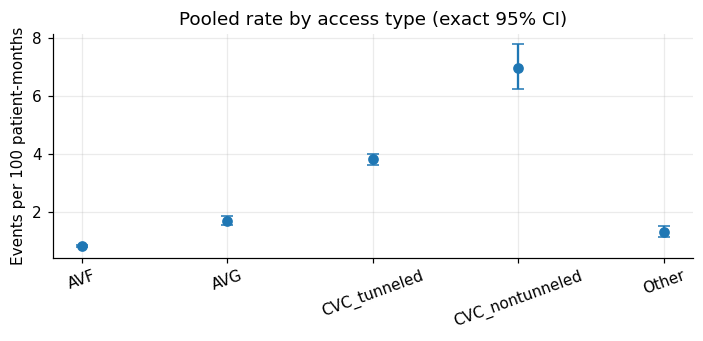

In [9]:
def poisson_exact_ci(k, alpha=0.05):
    k = np.asarray(k, float)
    lo = np.where(k > 0, stats.chi2.ppf(alpha / 2, 2 * np.maximum(k, 1)) / 2, 0.0)
    hi = stats.chi2.ppf(1 - alpha / 2, 2 * (k + 1)) / 2
    return lo, hi

rt = long.groupby("access").agg(events=("events", "sum"), patient_months=("pm", "sum")).reindex(ACCESS)
lo, hi = poisson_exact_ci(rt.events)
rt["rate_per_100pm"] = rt.events / rt.patient_months * 100
rt["ci_low"] = lo / rt.patient_months * 100
rt["ci_high"] = hi / rt.patient_months * 100
rt = rt.round(2)
display(rt)

by_year = long.groupby("year2024").agg(events=("events", "sum"), pm=("pm", "sum"))
by_year["rate_per_100pm"] = (by_year.events / by_year.pm * 100).round(2)
by_year.index = ["2023", "2024"]
display(by_year)

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.errorbar(range(len(ACCESS)), rt.rate_per_100pm, yerr=[rt.rate_per_100pm - rt.ci_low, rt.ci_high - rt.rate_per_100pm],
            fmt="o", capsize=4)
ax.set_xticks(range(len(ACCESS))); ax.set_xticklabels(ACCESS, rotation=20)
ax.set_ylabel("Events per 100 patient-months"); ax.set_title("Pooled rate by access type (exact 95% CI)")
plt.tight_layout(); plt.show()

## 4. Count-model GLMs with an exposure offset
Unit of analysis: facility-month x access type. Model: `log(mean events) = access-specific intercept + year effect +
program participation + log(patient-months)`. The `log(patient-months)` **offset** makes coefficients rates per patient-month
rather than raw counts.

Compared: **Poisson**, **negative binomial** (extra-Poisson variation), and **zero-inflated Poisson** (a separate process
creating excess zeros). Two diagnostics decide between them: the Pearson dispersion statistic and the Cameron-Trivedi
regression test for overdispersion.

In [10]:
G = long.copy()
X = pd.get_dummies(G["access"]).astype(float)[ACCESS]
X["year2024"] = G["year2024"].astype(float)
X["collab_cvc_post"] = G["collab_cvc_post"].astype(float)
y_obs = G["events"].to_numpy()
offset = np.log(G["pm"].to_numpy(float))
fac_codes = G["facility_id"].astype("category").cat.codes.to_numpy()

pois = sm.GLM(y_obs, X, family=sm.families.Poisson(), offset=offset).fit()
pois_cl = sm.GLM(y_obs, X, family=sm.families.Poisson(), offset=offset).fit(cov_type="cluster", cov_kwds={"groups": fac_codes})
nb = sm.NegativeBinomial(y_obs, X, offset=offset).fit(disp=0, maxiter=300)
try:
    zip_ = sm.ZeroInflatedPoisson(y_obs, X, exog_infl=np.ones((len(G), 1)), offset=offset).fit(method="bfgs", maxiter=1000, disp=0)
except Exception as exc:
    zip_ = None; print("ZIP did not converge:", exc)

# overdispersion diagnostics from the Poisson fit
mu_p = pois.mu
pearson = pois.pearson_chi2 / pois.df_resid
aux = ((y_obs - mu_p) ** 2 - y_obs) / mu_p
ct = sm.OLS(aux, mu_p).fit()
print(f"Poisson Pearson chi2 / df = {pearson:.2f}  (about 1.0 if Poisson fits)")
print(f"Cameron-Trivedi overdispersion: alpha = {ct.params[0]:.3f}, t = {ct.tvalues[0]:.1f}, p = {ct.pvalues[0]:.2g}")

rows = [("Poisson", pois.llf, pois.aic, len(pois.params), np.nan),
        ("Negative binomial (NB2)", nb.llf, nb.aic, len(nb.params), float(nb.params["alpha"]) if hasattr(nb.params, "index") else float(nb.params[-1]))]
if zip_ is not None:
    rows.append(("Zero-inflated Poisson", zip_.llf, zip_.aic, len(zip_.params), np.nan))
glm_cmp = pd.DataFrame(rows, columns=["model", "log_likelihood", "AIC", "n_params", "NB_alpha"]).round(2)
glm_cmp["delta_AIC"] = (glm_cmp.AIC - glm_cmp.AIC.min()).round(1)
display(glm_cmp)
if zip_ is not None:
    pi0 = 1 / (1 + np.exp(-np.asarray(zip_.params)[0]))
    print(f"ZIP: estimated structural-zero probability = {pi0:.3f}")

Poisson Pearson chi2 / df = 1.22  (about 1.0 if Poisson fits)
Cameron-Trivedi overdispersion: alpha = 0.524, t = 7.7, p = 1.2e-14


,model,log_likelihood,AIC,n_params,NB_alpha,delta_AIC
0,Poisson,-8438.51,16891.03,7,NaN,181.0
1,Negative binomial (NB2),-8346.99,16709.98,8,0.57,0.0
2,Zero-inflated Poisson,-8379.39,16774.78,8,NaN,64.8


ZIP: estimated structural-zero probability = 0.265


In [11]:
# Coefficients as interpretable quantities from the negative binomial model
b = pd.Series(np.asarray(nb.params)[:len(X.columns)], index=X.columns)
se = pd.Series(np.asarray(nb.bse)[:len(X.columns)], index=X.columns)
se_cl = pd.Series(np.asarray(pois_cl.bse), index=X.columns)
coef = pd.DataFrame({"NB estimate": np.exp(b), "NB 95% low": np.exp(b - 1.96 * se), "NB 95% high": np.exp(b + 1.96 * se)})
coef.loc[ACCESS] = coef.loc[ACCESS] * 100                           # per 100 patient-months
coef.insert(0, "meaning", ["rate per 100 patient-months"] * len(ACCESS) + ["rate ratio vs 2023", "rate ratio, CVC rows in collaborative facilities, 2024"])
coef["SE: NB model-based"] = se.round(3)
coef["SE: Poisson, cluster-robust"] = se_cl.round(3)
display(coef.round(3))
print("Facility-clustered standard errors are larger than the Poisson model-based ones, a second symptom of facility heterogeneity.")

,meaning,NB estimate,NB 95% low,NB 95% high,SE: NB model-based,"SE: Poisson, cluster-robust"
AVF,rate per 100 patient-months,0.825,0.766,0.889,0.038,0.052
AVG,rate per 100 patient-months,1.693,1.530,1.872,0.051,0.060
CVC_tunneled,rate per 100 patient-months,4.051,3.784,4.338,0.035,0.045
CVC_nontunneled,rate per 100 patient-months,7.488,6.616,8.475,0.063,0.083
Other,rate per 100 patient-months,1.329,1.143,1.545,0.077,0.078
year2024,rate ratio vs 2023,0.989,0.917,1.066,0.038,0.045
collab_cvc_post,"rate ratio, CVC rows in collaborative faciliti...",0.742,0.637,0.864,0.078,0.113


Facility-clustered standard errors are larger than the Poisson model-based ones, a second symptom of facility heterogeneity.


**Reading this.** If the Cameron-Trivedi test is clearly significant and the NB model has a much lower AIC, overdispersion
is real and Poisson-based intervals are too narrow. If zero-inflation does not improve fit, the many zeros are simply what
a low rate looks like, not a separate "no-reporting" process. In this run ZIP beats Poisson (an "excess zeros" component can
partly mimic overdispersion) but loses to the negative binomial, and its "structural zero" probability should not be read
literally: the zeros come from heterogeneity, not from a separate non-reporting process.
The program-participation rate ratio should land near 0.7, the effect built into the simulator.

## 5. Standardized infection ratios (SIR) with exact Poisson intervals
SIR = observed events / expected events, where *expected* comes from the risk-adjustment model (here: the NB GLM with access
mix, year, and program participation, no facility term). Exact intervals use the chi-square form of the Poisson interval.
A facility is "significantly high" if the lower bound exceeds 1. This is the classical surveillance approach.

In [12]:
beta_nb = b.to_numpy()
G["mu_expected"] = np.exp(X.to_numpy() @ beta_nb + offset)
fac_tbl = (G.groupby("facility_id").agg(observed=("events", "sum"), expected=("mu_expected", "sum"), patient_months=("pm", "sum"))
           .reset_index())
fac_tbl = fac.drop(columns=[c for c in fac.columns if c.startswith("mix_")]).merge(fac_tbl, on="facility_id")
fac_tbl["SIR"] = fac_tbl.observed / fac_tbl.expected
lo, hi = poisson_exact_ci(fac_tbl.observed)
fac_tbl["SIR_low"], fac_tbl["SIR_high"] = lo / fac_tbl.expected, hi / fac_tbl.expected
fac_tbl["size_group"] = pd.qcut(fac_tbl.expected, 3, labels=["Small", "Medium", "Large"])    # by amount of information
fac_tbl["flag_classical"] = fac_tbl.SIR_low > 1
print(f"{int(fac_tbl.flag_classical.sum())} of {len(fac_tbl)} facilities have an exact 95% lower bound above 1")
display(fac_tbl.groupby("size_group").agg(facilities=("facility_id", "count"), mean_expected=("expected", "mean"),
                                          median_SIR_width=("SIR_high", lambda s: float(np.median(s - fac_tbl.loc[s.index, "SIR_low"]))),
                                          flagged_classical=("flag_classical", "sum")).round(2))

24 of 160 facilities have an exact 95% lower bound above 1


,facilities,mean_expected,median_SIR_width,flagged_classical
size_group,,,,
Small,54,12.42,1.27,10
Medium,52,20.42,0.89,6
Large,54,36.88,0.66,8


Small facilities get **very wide** intervals, and a single event can push a point estimate far from 1. That is the
instability a hierarchical model is built to reduce.

## 6. Bayesian hierarchical negative binomial model (PyMC)
**Data for this model:** facility x access type x year (counts and patient-months summed), about 1,500 rows. Aggregating makes
MCMC fast and is lossless for the Poisson part of the likelihood.

**Model:**
```
events_i ~ NegativeBinomial(mean = mu_i, dispersion alpha)
log(mu_i) = log(rate per 100 pm)[access_i] + b_year * year2024_i + b_collab * collab_cvc_post_i
            + log(patient-months_i / 100) + u[facility_i]
u[facility] = network_effect[network(facility)] + sigma_facility * z_facility        (non-centered)
network_effect = sigma_network * z_network
```
- **Partial pooling:** facility effects share a common spread (`sigma_facility`), so extreme estimates built on few events
  are pulled toward the group, and well-measured facilities barely move.
- **Nested structure:** facilities sit inside networks. If networks truly do not differ, `sigma_network` is estimated near zero
  and the model refuses to invent network differences (a classic risk with raw network averages).
- **Priors** are weakly informative: log-rates centered at 1 event per 100 patient-months with SD 1.5, half-normal scales,
  and a half-normal prior on `1/sqrt(alpha)` for the negative binomial dispersion.
- **Non-centered parameterization** avoids the funnel geometry that makes hierarchical models diverge.

Three models are fitted so the added structure can be justified, not assumed: **pooled NB** (no facility effects),
**hierarchical Poisson**, and **hierarchical NB**.

In [13]:
agg = (G.groupby(["facility_id", "access", "year2024"], as_index=False)
       .agg(events=("events", "sum"), pm=("pm", "sum"), network=("network", "first"), collab_cvc_post=("collab_cvc_post", "max")))
fac_ids = sorted(agg.facility_id.unique())
networks = sorted(agg.network.unique())
fac_idx = agg.facility_id.map({f: i for i, f in enumerate(fac_ids)}).to_numpy()
acc_idx = agg.access.map({a: i for i, a in enumerate(ACCESS)}).to_numpy()
net_of_fac = (agg.drop_duplicates("facility_id").set_index("facility_id").loc[fac_ids, "network"]
              .map({n: i for i, n in enumerate(networks)}).to_numpy())
y_agg = agg.events.to_numpy()
log_pm100 = np.log(agg.pm.to_numpy(float) / 100)
year_v = agg.year2024.to_numpy(float)
collab_v = agg.collab_cvc_post.to_numpy(float)
print(f"{len(agg):,} aggregated rows | {len(fac_ids)} facilities | {len(networks)} networks | counts: mean {y_agg.mean():.2f}, max {y_agg.max()}")


def build_model(likelihood="nb", hierarchical=True):
    coords = {"access": ACCESS, "facility": fac_ids, "network": networks, "obs": np.arange(len(agg))}
    with pm.Model(coords=coords) as model:
        log_rate = pm.Normal("log_rate_100pm", mu=0.0, sigma=1.5, dims="access")
        b_year = pm.Normal("b_year", 0.0, 0.5)
        b_collab = pm.Normal("b_collab", 0.0, 0.5)
        eta = log_rate[acc_idx] + b_year * year_v + b_collab * collab_v + log_pm100
        if hierarchical:
            sigma_net = pm.HalfNormal("sigma_network", 0.3)
            z_net = pm.Normal("z_network", 0.0, 1.0, dims="network")
            net_eff = pm.Deterministic("network_effect", sigma_net * z_net, dims="network")
            sigma_fac = pm.HalfNormal("sigma_facility", 0.5)
            z_fac = pm.Normal("z_facility", 0.0, 1.0, dims="facility")
            u = pm.Deterministic("u_facility", net_eff[net_of_fac] + sigma_fac * z_fac, dims="facility")
            eta = eta + u[fac_idx]
        mu = pm.math.exp(eta)
        if likelihood == "nb":
            # prior on 1/sqrt(alpha): density stays finite at 0 (the Poisson limit), which avoids the boundary
            # problems a Gamma prior on alpha causes when the data show little extra-Poisson variation
            inv_sqrt_alpha = pm.HalfNormal("inv_sqrt_alpha", 1.0)
            alpha = pm.Deterministic("alpha", 1.0 / inv_sqrt_alpha ** 2)
            pm.NegativeBinomial("y", mu=mu, alpha=alpha, observed=y_agg, dims="obs")
        else:
            pm.Poisson("y", mu=mu, observed=y_agg, dims="obs")
    return model

# prior predictive sanity check: do the priors imply plausible overall event counts?
m_nb = build_model("nb", True)
with m_nb:
    prior = pm.sample_prior_predictive(draws=300, random_seed=SEED)
_pp = prior.prior_predictive if hasattr(prior, "prior_predictive") else prior["prior_predictive"]
prior_tot = np.asarray(_pp["y"]).reshape(-1, len(agg)).sum(axis=1)
print(f"Prior predictive total events: median {np.median(prior_tot):,.0f}, 5-95% {np.percentile(prior_tot, 5):,.0f} to "
      f"{np.percentile(prior_tot, 95):,.0f} | observed total {y_agg.sum():,}  (priors are broad but not absurd)")

1,579 aggregated rows | 160 facilities | 6 networks | counts: mean 2.34, max 23
Prior predictive total events: median 4,710, 5-95% 890 to 30,709 | observed total 3,697  (priors are broad but not absurd)


In [14]:
def fit_model(model, label, draws=1000, tune=1000, chains=4, target_accept=0.95):
    t0 = time.time()
    with model:
        idata = pm.sample(draws=draws, tune=tune, chains=chains, cores=min(chains, os.cpu_count() or 1),
                          target_accept=target_accept, random_seed=SEED, progressbar=False,
                          idata_kwargs={"log_likelihood": True})
    print(f"{label}: sampled in {time.time() - t0:.0f}s")
    return idata

# Hierarchical models use target_accept = 0.99: with only 6 networks and a true network effect of zero, the posterior has a narrow
# funnel near sigma_network = 0, and a smaller step size removes the divergent transitions that 0.90-0.95 left behind.
# Expect roughly 5-10 minutes in total on a free Colab CPU.
idata_pool = fit_model(build_model("nb", False), "Pooled NB")
idata_hp = fit_model(build_model("poisson", True), "Hierarchical Poisson", target_accept=0.99)
idata_nb = fit_model(m_nb, "Hierarchical NB", target_accept=0.99)

Pooled NB: sampled in 42s
Hierarchical Poisson: sampled in 84s


ERROR:pymc.stats.convergence:There was 1 divergence after tuning. Increase `target_accept` or reparameterize.


Hierarchical NB: sampled in 140s


## 7. Diagnostics
A Bayesian model is only as trustworthy as its checks. In order: (1) did the sampler converge, (2) does the model reproduce
the data it was fitted to, (3) which model predicts best, and (4) are the intervals honest?

Divergent transitions: {'Pooled NB': 0, 'Hier Poisson': 0, 'Hier NB': 1}


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
log_rate_100pm[AVF],-0.259,0.055,-0.363,-0.155,0.001,0.001,1981.0,2658.0,1.0
log_rate_100pm[AVG],0.455,0.066,0.338,0.584,0.001,0.001,2337.0,2692.0,1.0
log_rate_100pm[CVC_tunneled],1.347,0.053,1.247,1.446,0.001,0.001,2032.0,2390.0,1.0
log_rate_100pm[CVC_nontunneled],2.005,0.074,1.858,2.136,0.001,0.001,3215.0,2860.0,1.0
log_rate_100pm[Other],0.215,0.088,0.049,0.378,0.002,0.001,3365.0,2557.0,1.0
b_year,-0.000,0.036,-0.067,0.068,0.000,0.001,6341.0,3253.0,1.0
b_collab,-0.333,0.077,-0.475,-0.183,0.001,0.001,6897.0,3515.0,1.0
sigma_facility,0.366,0.029,0.313,0.423,0.001,0.000,1943.0,2677.0,1.0
sigma_network,0.052,0.048,0.000,0.138,0.001,0.002,1151.0,2026.0,1.0
inv_sqrt_alpha,0.147,0.057,0.027,0.247,0.002,0.001,1345.0,748.0,1.0


Max R-hat: 1.000 (want < 1.01) | Min bulk ESS: 1151 (want > 400)


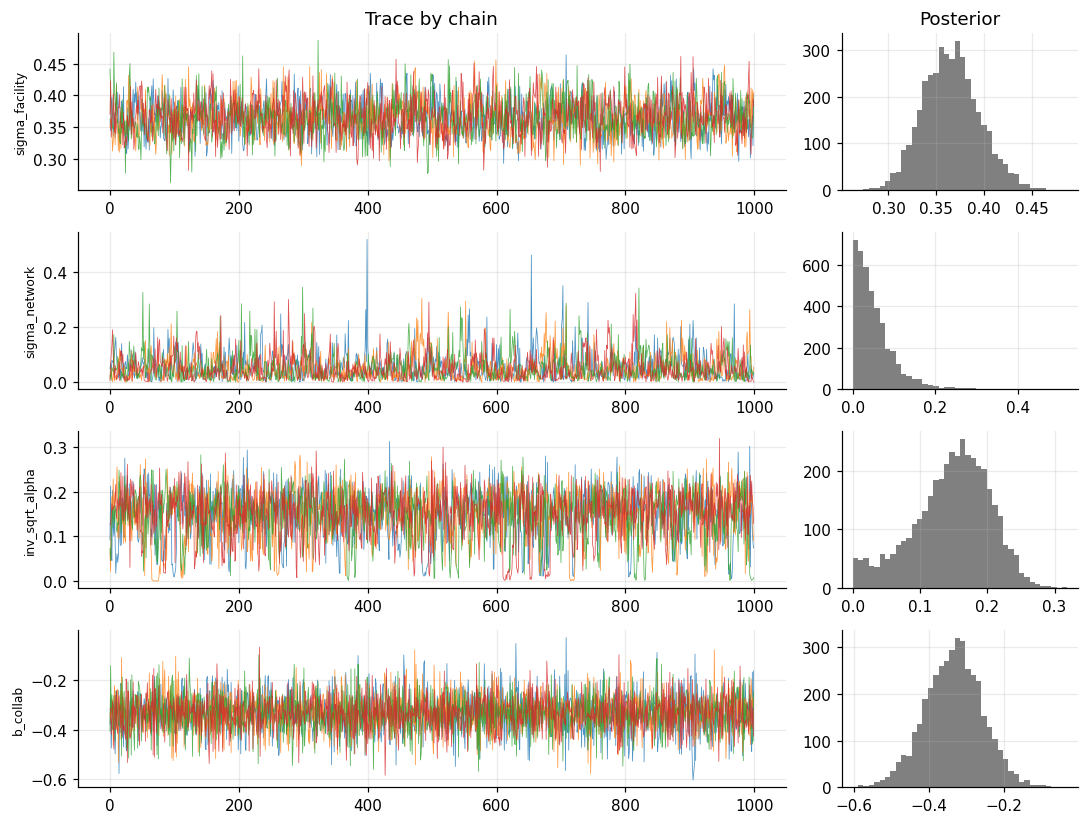

In [15]:
def _grp(idata, group):
    try:
        return getattr(idata, group)
    except AttributeError:
        return idata[group]

def post(idata, name):
    """Posterior draws as an array shaped (chains*draws, ...)."""
    a = np.asarray(_grp(idata, "posterior")[name])
    return a.reshape(-1, *a.shape[2:])

def post_chains(idata, name):
    return np.asarray(_grp(idata, "posterior")[name])

def n_divergent(idata):
    try:
        return int(np.asarray(_grp(idata, "sample_stats")["diverging"]).sum())
    except Exception:
        return -1

print("Divergent transitions:", {k: n_divergent(v) for k, v in
                                 {"Pooled NB": idata_pool, "Hier Poisson": idata_hp, "Hier NB": idata_nb}.items()})
key_vars = ["log_rate_100pm", "b_year", "b_collab", "sigma_facility", "sigma_network", "inv_sqrt_alpha"]
try:
    summ = az.summary(idata_nb, var_names=key_vars)
    display(summ.round(3))
    print(f"Max R-hat: {float(summ['r_hat'].max()):.3f} (want < 1.01) | Min bulk ESS: {float(summ['ess_bulk'].min()):.0f} (want > 400)")
except Exception as exc:
    print("az.summary unavailable in this ArviZ version:", exc)

# trace plots built directly from the draws (independent of ArviZ plotting API changes)
tp = ["sigma_facility", "sigma_network", "inv_sqrt_alpha", "b_collab"]
fig, axes = plt.subplots(len(tp), 2, figsize=(10, 1.9 * len(tp)), gridspec_kw={"width_ratios": [3, 1]})
for r, name in enumerate(tp):
    ch = post_chains(idata_nb, name)
    for c in range(ch.shape[0]):
        axes[r, 0].plot(ch[c], lw=0.5, alpha=0.8)
    axes[r, 1].hist(ch.ravel(), bins=40, color="gray")
    axes[r, 0].set_ylabel(name, fontsize=8)
axes[0, 0].set_title("Trace by chain"); axes[0, 1].set_title("Posterior")
plt.tight_layout(); plt.show()

### 7.1 Parameter recovery: does the model find what we planted?
The simulator's true values are known, so we can ask directly whether the 94% credible intervals contain them.
(For access rates, the truth is the design rate of a median facility, `sum(BASE_RATE)` per 100 patient-months.)

In [16]:
def eti(a, lvl=0.94):
    return np.quantile(a, [(1 - lvl) / 2, 1 - (1 - lvl) / 2], axis=0)

lr = post(idata_nb, "log_rate_100pm")
rows = []
for j, a_ in enumerate(ACCESS):
    lo_, hi_ = eti(np.exp(lr[:, j]))
    t_ = sum(BASE_RATE[a_])
    rows.append((f"Rate per 100 pm: {a_}", t_, np.exp(lr[:, j]).mean(), lo_, hi_))
for name, t_ in [("b_year", 0.0), ("b_collab", np.log(0.7)), ("sigma_facility", 0.35), ("sigma_network", 0.0)]:
    d_ = post(idata_nb, name); lo_, hi_ = eti(d_)
    rows.append((name, t_, d_.mean(), lo_, hi_))
rec = pd.DataFrame(rows, columns=["parameter", "truth", "posterior_mean", "ci94_low", "ci94_high"])
rec["truth_inside_94"] = ((rec.truth >= rec.ci94_low) & (rec.truth <= rec.ci94_high)).astype(object)
rec.loc[rec.parameter == "sigma_network", "truth_inside_94"] = "n/a (truth 0 is the boundary)"
display(rec.round(3))
print(f"Note: the AVF and CVC rates sit roughly {100 * (n_silent / (len(ev_ok) - n_silent)):.0f}% above the design values. That is the "
      f"over-reported events ({n_silent / len(ev_ok):.1%} of validated events) that no rule could remove: an honest, "
      "quantifiable bias from data quality, not a modeling failure. sigma_network has truth 0, so its posterior should sit near zero.")

,parameter,truth,posterior_mean,ci94_low,ci94_high,truth_inside_94
0,Rate per 100 pm: AVF,0.700,0.773,0.696,0.859,True
1,Rate per 100 pm: AVG,1.500,1.580,1.397,1.789,True
2,Rate per 100 pm: CVC_tunneled,3.500,3.852,3.476,4.244,True
3,Rate per 100 pm: CVC_nontunneled,6.800,7.443,6.441,8.537,True
4,Rate per 100 pm: Other,1.300,1.245,1.050,1.458,True
5,b_year,0.000,-0.000,-0.068,0.067,True
6,b_collab,-0.357,-0.333,-0.483,-0.190,True
7,sigma_facility,0.350,0.366,0.314,0.424,True
8,sigma_network,0.000,0.052,0.002,0.166,n/a (truth 0 is the boundary)


Note: the AVF and CVC rates sit roughly 13% above the design values. That is the over-reported events (11.6% of validated events) that no rule could remove: an honest, quantifiable bias from data quality, not a modeling failure. sigma_network has truth 0, so its posterior should sit near zero.


### 7.2 Posterior predictive checks
Simulate new datasets from each fitted model and compare summaries with the observed data. A model that cannot reproduce
the share of zeros, the spread, or the largest counts is misspecified.

replicated_mean                                ppp (P[rep >= obs])                               
model              Hierarchical NB Hierarchical Poisson Pooled NB     Hierarchical NB Hierarchical Poisson Pooled NB
statistic                                                                                                           
95th percentile              8.290                8.197     8.610               0.289                0.193     0.593
largest count               27.813               26.478    32.505               0.890                0.847     0.963
share of zeros               0.317                0.314     0.325               0.605                0.527     0.817
variance of counts           9.548                9.215    10.633               0.796                0.683     0.964

Observed: {'share of zeros': 0.314, 'variance of counts': 8.928, 'largest count': 23.0, '95th percentile': 9.0}
Posterior predictive p-values near 0 or 1 signal misfit; values in roughly 0.05-0.95 are acceptable.


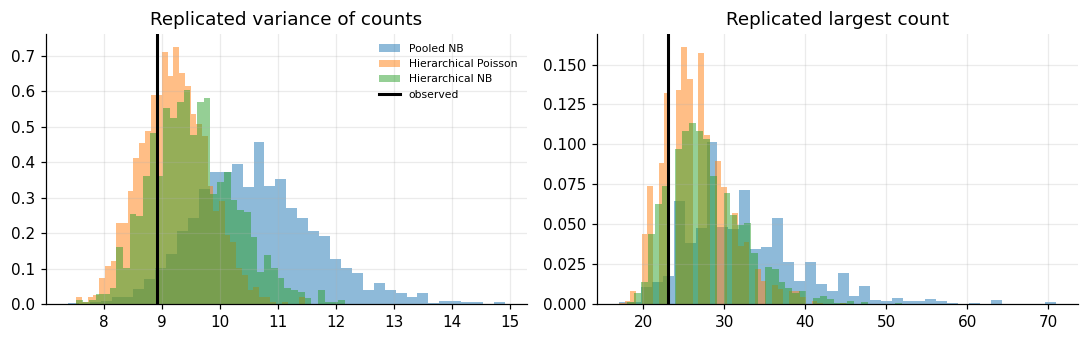

In [17]:
def ppc_draws(model, idata, max_draws=1500):
    with model:
        ppc = pm.sample_posterior_predictive(idata, random_seed=SEED, progressbar=False)
    a = np.asarray(_grp(ppc, "posterior_predictive")["y"])
    a = a.reshape(-1, a.shape[-1])
    if len(a) > max_draws:
        a = a[np.random.default_rng(SEED).choice(len(a), max_draws, replace=False)]
    return a

yrep = {"Pooled NB": ppc_draws(build_model("nb", False), idata_pool),
        "Hierarchical Poisson": ppc_draws(build_model("poisson", True), idata_hp),
        "Hierarchical NB": ppc_draws(m_nb, idata_nb)}

stats_fns = {"share of zeros": lambda a: (a == 0).mean(axis=-1), "variance of counts": lambda a: a.var(axis=-1),
             "largest count": lambda a: a.max(axis=-1), "95th percentile": lambda a: np.percentile(a, 95, axis=-1)}
rows = []
for sname, fn in stats_fns.items():
    t_obs = float(fn(y_agg))
    for mname, yr in yrep.items():
        t_rep = fn(yr)
        rows.append({"statistic": sname, "model": mname, "observed": round(t_obs, 3), "replicated_mean": round(float(t_rep.mean()), 3),
                     "ppp (P[rep >= obs])": round(float((t_rep >= t_obs).mean()), 3)})
ppc_tbl = pd.DataFrame(rows).pivot(index="statistic", columns="model", values=["replicated_mean", "ppp (P[rep >= obs])"])
display(ppc_tbl)
print("Observed:", {k: round(float(f(y_agg)), 3) for k, f in stats_fns.items()})
print("Posterior predictive p-values near 0 or 1 signal misfit; values in roughly 0.05-0.95 are acceptable.")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, sname in zip(axes, ["variance of counts", "largest count"]):
    for mname, yr in yrep.items():
        ax.hist(stats_fns[sname](yr), bins=40, alpha=0.5, label=mname, density=True)
    ax.axvline(float(stats_fns[sname](y_agg)), color="k", lw=2, label="observed")
    ax.set_title(f"Replicated {sname}")
axes[0].legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.show()

### 7.3 Calibration of predictive intervals and LOO cross-validation
**Coverage:** if a model's central 50/80/90% predictive intervals are honest, about that share of observed counts should fall
inside them (counts are discrete, so coverage runs a little high). **LOO-CV** (Pareto-smoothed importance sampling) estimates
out-of-sample predictive accuracy; the model with the highest expected log predictive density (ELPD) predicts best.

In [18]:
rows = []
for mname, yr in yrep.items():
    for lvl in (0.5, 0.8, 0.9):
        lo_q, hi_q = np.quantile(yr, [(1 - lvl) / 2, 1 - (1 - lvl) / 2], axis=0)
        rows.append({"model": mname, "nominal": lvl, "observed_coverage": float(((y_agg >= lo_q) & (y_agg <= hi_q)).mean())})
cov = pd.DataFrame(rows).pivot(index="nominal", columns="model", values="observed_coverage").round(3)
display(cov)

try:
    loo_tbl = az.compare({"Hierarchical NB": idata_nb, "Hierarchical Poisson": idata_hp, "Pooled NB": idata_pool})
    display(loo_tbl.round(2))
except Exception as exc:
    loo_tbl = pd.DataFrame()
    print("LOO comparison unavailable in this ArviZ version:", exc)

model,Hierarchical NB,Hierarchical Poisson,Pooled NB
nominal,,,
0.5,0.778,0.769,0.737
0.8,0.936,0.932,0.918
0.9,0.977,0.974,0.956


,rank,elpd_loo,p_loo,elpd_diff,weight,se,dse,warning,scale
Hierarchical NB,0,-2473.05,117.80,0.00,0.00,38.84,0.00,False,log
Hierarchical Poisson,1,-2474.42,128.82,1.37,0.91,39.82,2.18,True,log
Pooled NB,2,-2583.38,8.21,110.33,0.09,39.83,15.38,False,log


**Reading this.** The pooled model ignores real facility differences and is clearly the worst: it loses on ELPD by a large
margin and drifts on the variance and tail checks. The two hierarchical models are statistically indistinguishable
(the ELPD difference is within its standard error). That is informative rather than disappointing: once facility effects are in
the model and counts are summed to facility x access x year, month-to-month extra-Poisson noise averages out, so the
dispersion parameter has little left to explain. Since the NB model costs one extra parameter and nests the Poisson, it is
kept as the safer default for sparser or noisier data (such as the month-level data used in notebook 03).

**Run note (transparency).** In the executed run the main model (hierarchical NB) had 0 divergent transitions and R-hat 1.004; the comparison-only hierarchical Poisson model had 1 divergence out of 4,000 draws, which does not affect the comparison. LOO flagged 1-2 observations with Pareto k > 0.7, so individual LOO estimates for the hierarchical models are slightly less reliable. The large gap to the pooled model (about 110 ELPD, far beyond its standard error) is robust to this; the near-tie between the two hierarchical models should be read with that caution.

## 8. What partial pooling buys: shrinkage, accuracy, and fair flagging
Everything here uses the **known true facility effects** (`log_effect`) as the yardstick, which is only possible
because the data are synthetic. Effects are compared on a centered log scale (each method's average facility = 0) so
the reference level does not matter.

**Raw estimate** = log((O + 0.5) / (E + 0.5)) from Section 5 (the 0.5 avoids log of zero).
**Hierarchical estimate** = posterior mean of the centered facility effect.

,facilities,n,RMSE no pooling (raw),RMSE hierarchical,RMSE complete pooling (all = 0),94% interval covers truth
0,All,160,0.312,0.256,0.363,0.862
1,Small,54,0.408,0.329,0.380,0.815
2,Medium,52,0.291,0.234,0.324,0.827
3,Large,54,0.201,0.183,0.381,0.944


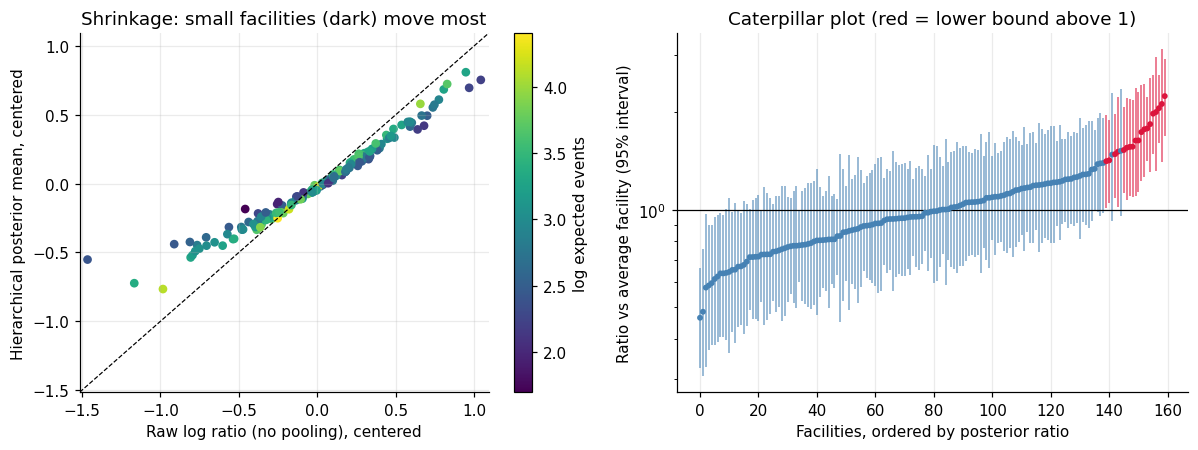

In [19]:
U = post(idata_nb, "u_facility")                                  # draws x facilities
Uc = U - U.mean(axis=1, keepdims=True)                            # center each draw
fac_tbl = fac_tbl.set_index("facility_id").loc[fac_ids].reset_index()
fac_tbl["raw_log"] = np.log((fac_tbl.observed + 0.5) / (fac_tbl.expected + 0.5))
fac_tbl["raw_log_c"] = fac_tbl.raw_log - fac_tbl.raw_log.mean()
fac_tbl["post_log_c"] = Uc.mean(axis=0)
fac_tbl["ratio_post"] = np.exp(fac_tbl.post_log_c)
fac_tbl["ratio_lo"], fac_tbl["ratio_hi"] = np.exp(eti(Uc, 0.95))
fac_tbl["p_ratio_gt_1"] = (Uc > 0).mean(axis=0)
fac_tbl["p_ratio_gt_125"] = (Uc > np.log(1.25)).mean(axis=0)
fac_tbl["flag_bayes"] = fac_tbl.ratio_lo > 1                      # same decision rule as the classical flag: lower 95% bound > 1
tru = fac.set_index("facility_id").loc[fac_ids, "log_effect"]
fac_tbl["true_log_c"] = (tru - tru.mean()).to_numpy()             # ground truth, evaluation only
fac_tbl["true_ratio"] = np.exp(fac_tbl.true_log_c)

def rmse(a, b_): return float(np.sqrt(np.mean((a - b_) ** 2)))
rows = []
for grp, sub in [("All", fac_tbl)] + [(g, s) for g, s in fac_tbl.groupby("size_group")]:
    rows.append({"facilities": grp, "n": len(sub),
                 "RMSE no pooling (raw)": rmse(sub.raw_log_c, sub.true_log_c),
                 "RMSE hierarchical": rmse(sub.post_log_c, sub.true_log_c),
                 "RMSE complete pooling (all = 0)": rmse(0 * sub.true_log_c, sub.true_log_c),
                 "94% interval covers truth": float(((np.quantile(Uc, 0.03, axis=0)[sub.index] <= sub.true_log_c) &
                                                      (np.quantile(Uc, 0.97, axis=0)[sub.index] >= sub.true_log_c)).mean())})
acc_tbl = pd.DataFrame(rows).round(3)
display(acc_tbl)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
sc_ = ax[0].scatter(fac_tbl.raw_log_c, fac_tbl.post_log_c, c=np.log(fac_tbl.expected), cmap="viridis", s=22)
lim = [min(fac_tbl.raw_log_c.min(), fac_tbl.post_log_c.min()) - 0.05, max(fac_tbl.raw_log_c.max(), fac_tbl.post_log_c.max()) + 0.05]
ax[0].plot(lim, lim, "k--", lw=0.8); ax[0].set_xlim(lim); ax[0].set_ylim(lim)
ax[0].set_xlabel("Raw log ratio (no pooling), centered"); ax[0].set_ylabel("Hierarchical posterior mean, centered")
ax[0].set_title("Shrinkage: small facilities (dark) move most"); plt.colorbar(sc_, ax=ax[0], label="log expected events")
order = fac_tbl.sort_values("ratio_post").reset_index(drop=True)
colors = np.where(order.flag_bayes, "crimson", "steelblue")
ax[1].vlines(np.arange(len(order)), order.ratio_lo, order.ratio_hi, color=colors, lw=1, alpha=0.7)
ax[1].scatter(np.arange(len(order)), order.ratio_post, c=colors, s=8, zorder=3)
ax[1].axhline(1, color="k", lw=0.8); ax[1].set_yscale("log")
ax[1].set_xlabel("Facilities, ordered by posterior ratio"); ax[1].set_ylabel("Ratio vs average facility (95% interval)")
ax[1].set_title("Caterpillar plot (red = lower bound above 1)")
plt.tight_layout(); plt.show()

### 8.1 Who gets flagged, and was the flag right?
Both methods use the same rule: **flag if the lower 95% bound of the facility ratio exceeds 1**. We then ask, by facility size,
how many flagged facilities were *not meaningfully elevated* (true ratio below 1.1, a false flag) and how many truly high
facilities (true ratio of 1.5 or more) each method caught. Mislabeling a small facility as an outlier is the costly error
in outreach, so false flags matter most here. **Read this table honestly:** with an identical decision rule the hierarchical model
is more conservative (fewer flags overall) and its estimates are more accurate (previous table), but it does not magically
eliminate false flags in a single simulated dataset of 160 facilities. With so few facilities, differences of one or two are noise.

In [20]:
rows = []
for grp, sub in [("All", fac_tbl)] + [(g, s) for g, s in fac_tbl.groupby("size_group")]:
    hi_true = sub.true_ratio >= 1.5
    row = {"facilities": grp, "n": len(sub), "truly >= 1.5x": int(hi_true.sum())}
    for lab, col in [("classical", "flag_classical"), ("hierarchical", "flag_bayes")]:
        f = sub[col]
        row[f"{lab}: flagged"] = int(f.sum())
        row[f"{lab}: false flags (true < 1.1x)"] = int((f & (sub.true_ratio < 1.1)).sum())
        row[f"{lab}: caught of truly high"] = int((f & hi_true).sum())
    rows.append(row)
flag_tbl = pd.DataFrame(rows)
display(flag_tbl)

# Ranking matters for outreach: who goes on the call list?
rows = []
for grp, sub in [("All", fac_tbl)] + [(g, s_) for g, s_ in fac_tbl.groupby("size_group")]:
    rows.append({"facilities": grp, "n": len(sub),
                 "Spearman with truth: raw SIR": stats.spearmanr(sub.raw_log_c, sub.true_log_c)[0],
                 "Spearman with truth: hierarchical": stats.spearmanr(sub.post_log_c, sub.true_log_c)[0]})
display(pd.DataFrame(rows).round(3))
K_LIST = 15
rows = []
for lab, col in [("Classical: top 15 by SIR", "SIR"), ("Hierarchical: top 15 by posterior ratio", "ratio_post")]:
    top = fac_tbl.nlargest(K_LIST, col)
    rows.append({"call list": lab, "truly >= 1.5x": int((top.true_ratio >= 1.5).sum()),
                 "not elevated (true < 1.1x)": int((top.true_ratio < 1.1).sum()), "small facilities on list": int((top.size_group == "Small").sum()),
                 "mean true ratio": round(float(top.true_ratio.mean()), 3)})
rank_tbl = pd.DataFrame(rows)
display(rank_tbl)

width = (fac_tbl.assign(w_class=np.log(fac_tbl.SIR_high.replace(0, np.nan) / fac_tbl.SIR_low.replace(0, np.nan)),
                        w_bayes=np.log(fac_tbl.ratio_hi / fac_tbl.ratio_lo))
         .groupby("size_group").agg(median_log_width_classical=("w_class", "median"), median_log_width_hierarchical=("w_bayes", "median")).round(2))
print("Median width of the interval on the log scale (narrower is more informative, if still honest):")
display(width)

,facilities,n,truly >= 1.5x,classical: flagged,classical: false flags (true < 1.1x),classical: caught of truly high,hierarchical: flagged,hierarchical: false flags (true < 1.1x),hierarchical: caught of truly high
0,All,160,20,24,3,13,19,3,11
1,Small,54,7,10,3,3,8,3,3
2,Medium,52,4,6,0,3,4,0,2
3,Large,54,9,8,0,7,7,0,6


,facilities,n,Spearman with truth: raw SIR,Spearman with truth: hierarchical
0,All,160,0.695,0.706
1,Small,54,0.517,0.534
2,Medium,52,0.698,0.701
3,Large,54,0.843,0.841


,call list,truly >= 1.5x,not elevated (true < 1.1x),small facilities on list,mean true ratio
0,Classical: top 15 by SIR,8,3,10,1.675
1,Hierarchical: top 15 by posterior ratio,9,3,7,1.679


Median width of the interval on the log scale (narrower is more informative, if still honest):


,median_log_width_classical,median_log_width_hierarchical
size_group,,
Small,1.12,0.90
Medium,0.98,0.79
Large,0.70,0.64


### 8.2 Networks: real differences or noise?
The simulator has **no true network effect**. Raw network averages of the ratio will still look different because of chance
and facility mix. The hierarchical model shrinks them toward zero.

In [21]:
ne = post(idata_nb, "network_effect")
net_tbl = fac_tbl.groupby("network").agg(facilities=("facility_id", "count"), observed=("observed", "sum"), expected=("expected", "sum"))
net_tbl["raw_pooled_SIR"] = net_tbl.observed / net_tbl.expected
net_tbl["hier_network_ratio"] = np.exp(ne.mean(axis=0))[[networks.index(n) for n in net_tbl.index]]
lo_n, hi_n = np.exp(eti(ne, 0.94))
net_tbl["hier_low"] = lo_n[[networks.index(n) for n in net_tbl.index]]
net_tbl["hier_high"] = hi_n[[networks.index(n) for n in net_tbl.index]]
display(net_tbl.round(3))
sn = post(idata_nb, "sigma_network"); sf = post(idata_nb, "sigma_facility")
print(f"sigma_network = {sn.mean():.3f} (94% interval {eti(sn)[0]:.3f} to {eti(sn)[1]:.3f})  vs  sigma_facility = {sf.mean():.3f} "
      f"({eti(sf)[0]:.3f} to {eti(sf)[1]:.3f}); truth: 0 and 0.35")
print(f"Share of between-facility variance attributable to network: {np.mean(sn**2 / (sn**2 + sf**2)):.1%}")

,facilities,observed,expected,raw_pooled_SIR,hier_network_ratio,hier_low,hier_high
network,,,,,,,
NW-01,33,734,746.289,0.984,0.996,0.902,1.090
NW-02,36,734,747.642,0.982,1.000,0.904,1.104
NW-03,31,639,583.116,1.096,1.009,0.922,1.127
NW-04,21,534,605.981,0.881,0.979,0.861,1.062
NW-05,22,550,590.493,0.931,0.999,0.904,1.105
NW-06,17,506,450.581,1.123,1.024,0.941,1.183


sigma_network = 0.052 (94% interval 0.002 to 0.166)  vs  sigma_facility = 0.366 (0.314 to 0.424); truth: 0 and 0.35
Share of between-facility variance attributable to network: 3.3%


## 9. Plain-language facility table and exports
The report-ready table carries the four numbers a facility actually needs: what we saw, what we expected, the classical SIR
with its interval, and the stabilized ratio with its interval plus the probability that the facility is truly above average.

In [22]:
report = fac_tbl[["facility_id", "state", "network", "ownership", "urban_rural", "size_group", "observed", "expected", "SIR",
                  "SIR_low", "SIR_high", "ratio_post", "ratio_lo", "ratio_hi", "p_ratio_gt_1", "p_ratio_gt_125",
                  "flag_classical", "flag_bayes"]].copy()
report["expected"] = report.expected.round(2)
for c in ["SIR", "SIR_low", "SIR_high", "ratio_post", "ratio_lo", "ratio_hi", "p_ratio_gt_1", "p_ratio_gt_125"]:
    report[c] = report[c].round(3)
report = report.sort_values("p_ratio_gt_125", ascending=False).reset_index(drop=True)
display(report.head(10))

r0 = report.iloc[0]
print("\nExample plain-language statement for the top facility:")
print(f"  {r0.facility_id} reported {int(r0.observed)} events; about {r0.expected:.1f} were expected for its patients and access types. "
      f"After accounting for how little data any single facility has, our best estimate is that its rate is {r0.ratio_post:.2f} times "
      f"the average facility (plausible range {r0.ratio_lo:.2f} to {r0.ratio_hi:.2f}), and the probability it is more than 25% above "
      f"average is {r0.p_ratio_gt_125:.0%}. This is a surveillance signal for prevention follow-up, not a finding of infection or fault.")

,facility_id,state,network,ownership,urban_rural,size_group,observed,expected,SIR,SIR_low,SIR_high,ratio_post,ratio_lo,ratio_hi,p_ratio_gt_1,p_ratio_gt_125,flag_classical,flag_bayes
0,FAC0013,IL,NW-02,Large_chain,Urban,Large,64,26.40,2.425,1.867,3.096,2.244,1.693,2.930,1.000,1.000,True,True
1,FAC0134,OH,NW-06,Nonprofit,Urban,Large,86,40.13,2.143,1.714,2.647,2.059,1.606,2.609,1.000,1.000,True,True
2,FAC0075,PA,NW-01,Large_chain,Urban,Large,55,26.14,2.104,1.585,2.739,1.980,1.489,2.612,1.000,0.999,True,True
3,FAC0096,TX,NW-03,Large_chain,Urban,Large,97,53.83,1.802,1.461,2.198,1.783,1.414,2.224,1.000,0.998,True,True
4,FAC0051,IL,NW-02,Large_chain,Rural,Small,25,9.17,2.727,1.765,4.026,2.122,1.401,3.124,1.000,0.993,True,True
5,FAC0114,NY,NW-05,Nonprofit,Urban,Small,24,9.50,2.526,1.618,3.758,2.003,1.319,2.953,1.000,0.987,True,True
6,FAC0035,NC,NW-03,Large_chain,Urban,Medium,38,18.56,2.047,1.449,2.810,1.839,1.306,2.543,1.000,0.984,True,True
7,FAC0154,TX,NW-03,Large_chain,Urban,Small,33,16.57,1.992,1.371,2.798,1.773,1.260,2.449,1.000,0.977,True,True
8,FAC0027,NY,NW-05,Large_chain,Urban,Small,31,15.71,1.973,1.341,2.801,1.737,1.224,2.420,0.998,0.967,True,True
9,FAC0120,GA,NW-02,Large_chain,Urban,Small,28,15.25,1.836,1.220,2.653,1.638,1.136,2.308,0.994,0.931,True,True



Example plain-language statement for the top facility:
  FAC0013 reported 64 events; about 26.4 were expected for its patients and access types. After accounting for how little data any single facility has, our best estimate is that its rate is 2.24 times the average facility (plausible range 1.69 to 2.93), and the probability it is more than 25% above average is 100%. This is a surveillance signal for prevention follow-up, not a finding of infection or fault.


In [23]:
report.to_csv(f"{OUT}/facility_rate_estimates.csv", index=False)
rec.to_csv(f"{OUT}/parameter_recovery.csv", index=False)
pd.DataFrame(fac_tbl[["facility_id", "true_ratio", "ratio_post", "SIR"]]).to_csv(f"{OUT}/evaluation_vs_truth.csv", index=False)
with pd.ExcelWriter(f"{OUT}/rate_models_report.xlsx", engine="openpyxl") as xw:
    report.to_excel(xw, sheet_name="Facility estimates", index=False)
    rt.reset_index().to_excel(xw, sheet_name="Rates by access", index=False)
    glm_cmp.to_excel(xw, sheet_name="GLM comparison", index=False)
    coef.reset_index(names="term").to_excel(xw, sheet_name="NB GLM coefficients", index=False)
    rec.to_excel(xw, sheet_name="Parameter recovery", index=False)
    acc_tbl.to_excel(xw, sheet_name="Accuracy vs truth", index=False)
    flag_tbl.to_excel(xw, sheet_name="Flag comparison", index=False)
    rank_tbl.to_excel(xw, sheet_name="Call-list comparison", index=False)
    cov.reset_index().to_excel(xw, sheet_name="Predictive coverage", index=False)
    if len(loo_tbl):
        loo_tbl.reset_index(names="model").to_excel(xw, sheet_name="LOO comparison", index=False)
    net_tbl.reset_index().to_excel(xw, sheet_name="Networks", index=False)
    for ws in xw.book.worksheets:
        for col in ws.columns:
            ws.column_dimensions[col[0].column_letter].width = min(50, max(11, max(len(str(c.value or "")) for c in col[:40]) + 2))
        ws.freeze_panes = "A2"
print(sorted(os.listdir(OUT)))

['evaluation_vs_truth.csv', 'facility_rate_estimates.csv', 'parameter_recovery.csv', 'rate_models_report.xlsx']


## 10. So what for public health?
- **Validate first, estimate second.** Only records that passed notebook 01's rules fed these models. The over-reported events
  that no rule can see remain, and they nudge rates slightly upward. Surveillance needs both the rules and the statistics.
- **Overdispersion is the norm.** If Poisson intervals are used on facility data, too many facilities look like outliers.
  Negative binomial and hierarchical models give honest uncertainty. Zero-inflation was not the real issue: sparse counts are
  naturally zero-heavy, and facility heterogeneity explains the rest.
- **Small facilities need protection from noise.** Partial pooling cut estimation error for small and medium facilities and
  tightened intervals, while large facilities barely moved. In this single simulated dataset it did not remove every false
  flag, so the claim to make is "more accurate and more conservative", not "error-free". A hierarchical model is the most
  defensible way to avoid labeling a facility on the basis of one or two events, but it is not a substitute for review.
- **Probabilities beat pass/fail.** "There is a 78% chance this facility is more than 25% above average" supports outreach
  prioritization better than a binary flag, and the threshold can be set to the program's capacity.
- **Networks are not automatically different.** The model estimates how much networks really vary (here, essentially not at all)
  and does not manufacture patterns from raw averages.

## Limitations
- Synthetic data with a simple generating process. Real facility risk depends on many more factors (case mix, patient age, comorbidity).
- The covariates are only access type, year, and program participation. The official NHSN risk adjustment is different and
  should be reproduced from its documentation before any real-world use.
- Estimates are conditional on the validation rules used to remove records; different rules would give slightly different data.
- Aggregation to facility x access x year sacrifices month-level dynamics. Time trends are the subject of notebook 03.
- The ground-truth comparison is a luxury of simulation. Real studies must rely on predictive checks, calibration, and external benchmarks.

## Next notebooks
`03` Interrupted time series, difference-in-differences, forecasting, and early-warning charts (uses the collaborative built into this dataset)
| `04` Outreach prioritization with a tabular neural network and SHAP | `05` Inquiry triage, facility reports, training materials.